# (선택) 코드로 파인튜닝하기 — GPU 필요
강의장에서는 **Unsloth Studio**(화면 클릭)로 학습해요. 이 노트북은 같은 설정을 코드로 돌리는 **대체 방법**이에요.

| 어디서 | 준비 |
|---|---|
| Colab | 런타임 → 런타임 유형 변경 → **T4 GPU** |
| 내 컴퓨터 | NVIDIA GPU + Unsloth 설치 (RTX 50 시리즈는 CUDA 12.8 이상 PyTorch 필요) |

준비물: `train.jsonl`, `eval.jsonl`, `test.jsonl` (split_data.ipynb로 만든 파일) — 같은 폴더에 두기
⚠️ 학습한 모델·GGUF 파일은 온라인(GitHub 등)에 올리지 않아요.

In [5]:
# ▶ 환경 준비 — Colab · VS Code 공통, 맨 처음 한 번 실행
import os, sys, platform, subprocess
IN_COLAB = 'google.colab' in sys.modules

def gpu_info():
    try:
        r = subprocess.run(['nvidia-smi', '--query-gpu=name,memory.total', '--format=csv,noheader'],
                           capture_output=True, text=True, timeout=10)
        return r.stdout.strip() or None
    except Exception:
        return None

GPU = gpu_info()
print('실행 위치:', 'Colab' if IN_COLAB else f'내 컴퓨터 ({platform.system()})')
print('GPU:', GPU or '없음 → CPU로 실행 (이 노트북은 CPU로도 충분해요)')

# (선택) pandas를 GPU로 — Colab GPU 런타임 또는 Linux/WSL에 cuDF가 있을 때만
USE_GPU_PANDAS = False          # True로 바꾸고 이 칸을 다시 실행
if USE_GPU_PANDAS and GPU:
    try:
        get_ipython().run_line_magic('load_ext', 'cudf.pandas')
        print('pandas → GPU(cuDF) 사용')
    except Exception as e:
        print('cuDF를 쓸 수 없어 일반 pandas로 실행:', type(e).__name__)

# 한글 글꼴: Colab은 나눔고딕 설치, 윈도우는 맑은 고딕, 맥은 애플고딕
import matplotlib.pyplot as plt
from matplotlib import font_manager as fm
if IN_COLAB:
    nanum = '/usr/share/fonts/truetype/nanum/NanumGothic.ttf'
    if not os.path.exists(nanum):
        subprocess.run('apt-get -qq install -y fonts-nanum > /dev/null', shell=True)
    fm.fontManager.addfont(nanum)
    plt.rcParams['font.family'] = 'NanumGothic'
elif platform.system() == 'Windows':
    plt.rcParams['font.family'] = 'Malgun Gothic'
elif platform.system() == 'Darwin':
    plt.rcParams['font.family'] = 'AppleGothic'
else:                                   # 리눅스·WSL: 설치된 한글 글꼴 찾기
    ko = [f.name for f in fm.fontManager.ttflist if 'Nanum' in f.name or 'CJK KR' in f.name]
    if ko: plt.rcParams['font.family'] = ko[0]
plt.rcParams['axes.unicode_minus'] = False
print('한글 글꼴:', plt.rcParams['font.family'])

실행 위치: 내 컴퓨터 (Windows)
GPU: NVIDIA GeForce RTX 5070 Laptop GPU, 8151 MiB
한글 글꼴: ['Malgun Gothic']


In [6]:
assert GPU, 'GPU가 없어요. Colab은 T4 GPU 런타임으로 바꾸고, 내 컴퓨터는 Unsloth Studio를 쓰세요.'

In [11]:
import torch
print(torch.__version__, torch.cuda.is_available(), torch.version.cuda)

2.14.1+cpu False None


In [12]:
%pip install --force-reinstall --no-deps torch torchvision --index-url https://download.pytorch.org/whl/cu130

Looking in indexes: https://download.pytorch.org/whl/cu130
   ---------------------------------------- 0.0/2.0 GB ? eta -:--:--
   ---------------------------------------- 0.0/2.0 GB 115.0 MB/s eta 0:00:18
    --------------------------------------- 0.0/2.0 GB 116.3 MB/s eta 0:00:17
   - -------------------------------------- 0.1/2.0 GB 112.8 MB/s eta 0:00:18
   - -------------------------------------- 0.1/2.0 GB 112.4 MB/s eta 0:00:17
   -- ------------------------------------- 0.1/2.0 GB 111.9 MB/s eta 0:00:17
   -- ------------------------------------- 0.1/2.0 GB 111.8 MB/s eta 0:00:17
   --- ------------------------------------ 0.2/2.0 GB 112.4 MB/s eta 0:00:17
   --- ------------------------------------ 0.2/2.0 GB 111.8 MB/s eta 0:00:17
   ---- ----------------------------------- 0.2/2.0 GB 111.4 MB/s eta 0:00:16
   ---- ----------------------------------- 0.2/2.0 GB 111.5 MB/s eta 0:00:16
   ----- ---------------------------------- 0.3/2.0 GB 111.8 MB/s eta 0:00:16
   ----- -----

  You can safely remove it manually.
  You can safely remove it manually.


In [13]:
import torch
print(torch.__version__, torch.cuda.is_available(), torch.version.cuda)

2.14.1+cpu False None


In [14]:
%pip install --force-reinstall --no-deps torch torchvision --index-url https://download.pytorch.org/whl/cu128

Looking in indexes: https://download.pytorch.org/whl/cu128
  Using cached torch-2.11.0%2Bcu128-cp312-cp312-win_amd64.whl.metadata (29 kB)
Using cached torch-2.11.0%2Bcu128-cp312-cp312-win_amd64.whl (2753.2 MB)
   ---------------------------------------- 0.0/9.6 MB ? eta -:--:--
   ---------------------------------------- 9.6/9.6 MB 66.6 MB/s  0:00:00

  Attempting uninstall: torchvision

    Found existing installation: torchvision 0.29.1+cu130

    Uninstalling torchvision-0.29.1+cu130:

      Successfully uninstalled torchvision-0.29.1+cu130

   ---------------------------------------- 0/2 [torchvision]
   ---------------------------------------- 0/2 [torchvision]
   ---------------------------------------- 0/2 [torchvision]
   ---------------------------------------- 0/2 [torchvision]
   ---------------------------------------- 0/2 [torchvision]
   ---------------------------------------- 0/2 [torchvision]
   ---------------------------------------- 0/2 [torchvision]
   ------------

In [1]:
import torch
print(torch.__version__, torch.cuda.is_available(), torch.version.cuda)

2.11.0+cu128 True 12.8


In [2]:
# 설치 (Colab은 매번, 내 컴퓨터는 한 번만) — 몇 분 걸려요
try:
    import unsloth
    print('이미 있어요:', unsloth.__version__)
except ImportError:
    print('.venv에는 unsloth 없어요')

🦥 Unsloth: Will patch your computer to enable 2x faster free finetuning.


W1112 05:57:37.163000 27788 Lib\site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.
[unsloth_zoo.log|WARNING]Unsloth: Triton 3.9.0 has no block pointers, which torch 2.11.0+cu128's flex_decoding needs; short queries use the main flex kernel instead. Install the Triton your torch pins to get flex_decoding back.


🦥 Unsloth Zoo will now patch everything to make training faster!
이미 있어요: 2026.11.4


In [ ]:
# 설치 (Colab은 매번, 내 컴퓨터는 한 번만) — 몇 분 걸려요
# %pip install -q unsloth

Note: you may need to restart the kernel to use updated packages.


## 1. 기본 모델 불러오기 — 4bit로 작게 (QLoRA)

In [3]:
from unsloth import FastLanguageModel
model, tokenizer = FastLanguageModel.from_pretrained(
    model_name='unsloth/Qwen2.5-3B-Instruct-bnb-4bit',
    max_seq_length=2048,
    load_in_4bit=True,
)
model = FastLanguageModel.get_peft_model(
    model, r=16, lora_alpha=32, lora_dropout=0,
    target_modules=['q_proj', 'k_proj', 'v_proj', 'o_proj', 'gate_proj', 'up_proj', 'down_proj'],
    use_gradient_checkpointing='unsloth', random_state=42,
)

==((====))==  Unsloth 2026.11.4: Fast Qwen2 patching. Transformers: 5.17.0.
   \\   /|    NVIDIA GeForce RTX 5070 Laptop GPU. Num GPUs = 1. Max memory: 7.933 GB. Platform: Windows.
O^O/ \_/ \    Torch: 2.11.0+cu128. CUDA: 12.0. CUDA Toolkit: 12.8. Triton: 3.9.0
\        /    Bfloat16 = TRUE. FA [Xformers = 0.0.35. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!


Loading weights:   0%|          | 0/434 [00:00<?, ?it/s]

Unsloth 2026.11.4 patched 36 layers with 36 QKV layers, 36 O layers and 36 MLP layers.


Unsloth: compiling each transformer block as one region (Qwen2DecoderLayer).


## 2. 데이터를 대화 형식으로 바꾸기

In [4]:
from datasets import load_dataset
ds = load_dataset('json', data_files={'train': 'train.jsonl', 'eval': 'eval.jsonl'})

def to_text(ex):
    msgs = [{'role': 'user', 'content': ex['instruction'] + '\n\n' + ex['input']},
            {'role': 'assistant', 'content': ex['output']}]
    return {'text': tokenizer.apply_chat_template(msgs, tokenize=False)}

ds = ds.map(to_text)
print(ds)

Generating train split: 0 examples [00:00, ? examples/s]

Generating eval split: 0 examples [00:00, ? examples/s]

Map:   0%|          | 0/262 [00:00<?, ? examples/s]

Map:   0%|          | 0/46 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['instruction', 'input', 'output', 'text'],
        num_rows: 262
    })
    eval: Dataset({
        features: ['instruction', 'input', 'output', 'text'],
        num_rows: 46
    })
})


## 3. 학습 — Studio와 같은 설정 (에포크 2 · 배치 2×누적 4 · LR 2e-4)

In [5]:
from trl import SFTTrainer, SFTConfig
trainer = SFTTrainer(
    model=model, tokenizer=tokenizer,
    train_dataset=ds['train'], eval_dataset=ds['eval'],
    args=SFTConfig(
        dataset_text_field='text', max_seq_length=2048,
        per_device_train_batch_size=2, gradient_accumulation_steps=4,
        num_train_epochs=2, learning_rate=2e-4,
        optim='adamw_8bit', weight_decay=0.01, lr_scheduler_type='linear',
        logging_steps=1, eval_strategy='epoch',
        seed=42, output_dir='outputs', report_to='none',
    ),
)
stats = trainer.train()

Unsloth: Tokenizing ["text"]:   0%|          | 0/262 [00:00<?, ? examples/s]

Unsloth: Tokenizing ["text"]:   0%|          | 0/46 [00:00<?, ? examples/s]

The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'bos_token_id': None}.


🦥 Unsloth: Padding-free auto-enabled, enabling faster training.


==((====))==  Unsloth - 2x faster free finetuning | Num GPUs used = 1
   \\   /|    Num examples = 262 | Num Epochs = 2 | Total steps = 66
O^O/ \_/ \    Batch size per device = 2 | Gradient accumulation steps = 4
\        /    Data Parallel GPUs = 1 | Total batch size (2 x 4 x 1) = 8
 "-____-"     Trainable parameters = 29,933,568 of 3,115,872,256 (0.96% trained)


Unsloth: Will smartly offload gradients to save VRAM!
Unsloth: packed / padding-free rows run each transformer block uncompiled; only unpacked batches use the compiled blocks.
Unsloth: Double buffering enabled (parallel H2D + compute) for backward pass.


Epoch,Training Loss,Validation Loss
1,1.715312,1.729755
2,1.619012,1.660154


Unsloth: Not an error, but `num_items_in_batch` could not be counted for Qwen2ForCausalLM's labels, so each micro-batch loss is a mean.
Using gradient accumulation will be very slightly less accurate.
Read more on gradient accumulation issues here: https://unsloth.ai/blog/gradient
Unsloth: Restored added_tokens_decoder metadata in outputs\checkpoint-66\tokenizer_config.json.


NameError: name 'plt' is not defined

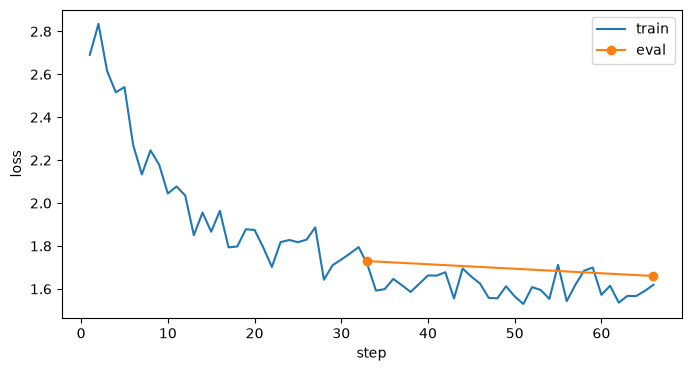

In [6]:
# loss 그래프 — train은 내려가는데 eval이 올라가면 외우기 시작(과적합)
import pandas as pd
log = pd.DataFrame(trainer.state.log_history)
ax = log.dropna(subset=['loss']).plot(x='step', y='loss', label='train', figsize=(8, 4))
if 'eval_loss' in log:
    log.dropna(subset=['eval_loss']).plot(x='step', y='eval_loss', label='eval', ax=ax, marker='o')
ax.set_ylabel('loss'); plt.show()

## 4. 시험 문제로 확인 — 본문에 없는 숫자·원인을 지어내지 않았나?

In [7]:
FastLanguageModel.for_inference(model)
test = pd.read_json('test.jsonl', lines=True)
for _, r in test.iterrows():
    msgs = [{'role': 'user', 'content': r['instruction'] + '\n\n' + r['input']}]
    ids = tokenizer.apply_chat_template(msgs, add_generation_prompt=True, return_tensors='pt').to('cuda')
    out = model.generate(input_ids=ids, max_new_tokens=128, do_sample=False)
    print('모델:', tokenizer.decode(out[0][ids.shape[1]:], skip_special_tokens=True))
    print('정답:', r['output']); print('-' * 40)

Both `max_new_tokens` (=128) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=128) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


모델: 축구대표팀이 내일 일본과의 평가전을 앞두고 임시 감독인 모레노 감독이 주장 교체 가능성을 제기하면서, 96년생 선수들 사이에 갈등이 불거지고 있습니다. 손흥민과 황인범, 황희찬 등 96년생 선수들은 모레노 감독의 결정에 불만을 나타냈는데요. 박재웅 기자가 전해드립니다.
정답: 다음 달 중동 원정에 나서는 축구대표팀 명단이 발표됐습니다. 모레노 감독은 손흥민과 은퇴 소동을 벌인 96년생 3인방 선수들을 모두 발탁해 정면 돌파 의지를 내비쳤는데요. 주장은 손흥민이라고 못을 박았습니다. 박재웅 기자입니다.
----------------------------------------


Both `max_new_tokens` (=128) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


모델: 프로야구 삼성이 12년 만에 통산 9번째 우승을 차지했습니다. 8년 만에 나온 정규시즌 2위의 역전 우승에 홈팬들은 열광했습니다. 김태운 기자가 전합니다.
정답: 프로야구 한국 시리즈에서 삼성이 kt를 꺾고 통산 9번째 우승을 달성했습니다. 정규시즌 2위로 열세가 예상됐지만 1패 뒤 4연승으로 짜릿한 역전 우승을 이루며, 12년 만에 정상에 복귀했는데요. 김태운 기자가 보도합니다.
----------------------------------------


Both `max_new_tokens` (=128) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


모델: 아시안게임 여자 기계체조 10년 만에 금메달을 획득한 황서현 선수가 오늘 귀국했습니다. 7살부터 10년간 힘든 훈련 끝에 꿈을 이룬 황서현은, 학교생활을 병행하며 다음 도약을 준비하고 있습니다. 곽승규 기자입니다.
정답: 여자 기계체조 평균대에서 금메달을 따낸 '작은 거인' 황서현 선수가 하루 사이에 말 그대로 깜짝 스타로 떠올랐습니다. 오늘 입국장에서도 가장 큰 주목을 받았던 황서현의 금메달 뒷이야기를 일본 나고야 현지에서 곽승규 기자가 전합니다.
----------------------------------------


Both `max_new_tokens` (=128) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


모델: 축구대표팀이 최근 2연패로 1차전 승리를 잃었습니다. 김민재 선수가 불만을 터뜨렸는데요. 모레노 감독이 맡은 6경기 중 절반인 3경기에서 선수들의 불만이 터져나오면서 모레노호는 시작부터 흔들리고 있습니다. 박재웅 기자입니다.
정답: 축구대표팀이 우루과이에 완패한 데 이어 베네수엘라와도 졸전 끝에 득점 없이 비겼는데요. 김민재 선수가 축구화를 집어던지며 화를 낸 뒤 경기 후 작심발언을 쏟아냈습니다. 박재웅 기자입니다.
----------------------------------------
모델: 여자 복싱 58kg급 안세영 선수가 일본의 오쿠하라를 꺾고 결승에 올랐습니다. 준결승에서 21대 12으로 완승을 거둔 안세영은 두 번째 게임에서도 7대 3까지 끌려갔지만, 7연속 득점을 기록하며 경기를 뒤집었습니다. 안세영은 대회 3회 연속 우승을 노리고 있습니다.
정답: 배드민턴 안세영 선수가 49연승 행진 속에 프랑스오픈 결승에 올랐는데요. 대회 3연패와 함께 시즌 10번째 우승을 눈앞에 두게 됐습니다.
----------------------------------------


## 5. (더 해보기) GGUF로 내보내 Ollama에서 쓰기

In [8]:
model.save_pretrained_gguf('lead_model', tokenizer, quantization_method='q4_k_m')
# 만들어진 .gguf 파일을 내려받아 Modelfile 첫 줄에  FROM ./파일이름.gguf
# 터미널: ollama create 내모델이름 -f Modelfile

Unsloth: Merging model weights to 16-bit format...


Unsloth: Restored added_tokens_decoder metadata in lead_model\tokenizer_config.json.


Found HuggingFace hub cache directory: C:\Users\EZ\.cache\huggingface\hub


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 1 files:   0%|          | 0/1 [00:00<?, ?it/s]

Checking cache directory for required files...



Unsloth: Copying 2 files from cache to `lead_model`: 100%|██████████| 2/2 [00:00<00:00, 2002.53it/s]


Successfully copied all 2 files from cache to `lead_model`
Checking cache directory for required files...
Cache check failed: tokenizer.model not found in local cache.
Not all required files found in cache. Will proceed with downloading.



Unsloth: Preparing safetensor model files: 100%|██████████| 2/2 [00:00<00:00, 3930.93it/s]



Unsloth: Merging weights into 16bit: 100%|██████████| 2/2 [00:13<00:00,  6.79s/it]


Unsloth: Merge process complete. Saved to `c:\workspace\ai-datajournalism-labs\4_파인튜닝\lead_model`
Unsloth: Converting to GGUF format...
==((====))==  Unsloth: Conversion from HF to GGUF information
   \\   /|    [0] Installing llama.cpp might take 3 minutes.
O^O/ \_/ \    [1] Converting HF to GGUF bf16 might take 3 minutes.
\        /    [2] Converting GGUF bf16 to ['q4_k_m'] might take 10 minutes each.
 "-____-"     In total, you will have to wait at least 16 minutes.

Unsloth: llama.cpp found in the system. Skipping installation.
Unsloth: Preparing converter script...
Unsloth: [1] Converting model into bf16 GGUF format.
This might take 3 minutes...
Unsloth: Initial conversion completed! Files: ['lead_model_gguf\\Qwen2.5-3B-Instruct.BF16.gguf']
Unsloth: [2] Converting GGUF bf16 into q4_k_m. This might take 10 minutes...
Unsloth: Model files cleanup...
Unsloth: All GGUF conversions completed successfully!
Generated files: ['lead_model_gguf\\Qwen2.5-3B-Instruct.Q4_K_M.gguf']
Unsloth: ex

{'save_directory': 'lead_model',
 'gguf_directory': 'lead_model_gguf',
 'gguf_files': ['lead_model_gguf\\Qwen2.5-3B-Instruct.Q4_K_M.gguf'],
 'modelfile_location': 'lead_model_gguf\\Modelfile',
 'want_full_precision': False,
 'is_vlm': False,
 'fix_bos_token': False}